# Práctica 2

Optimizador y nº de épocas de partida: **Adam, 5 épocas**, que fue la configuración ganadora en la Práctica 1 (mejor compromiso rendimiento/tiempo/generalización). Así se aísla la arquitectura como única variable en la primera tanda de experimentos.

In [1]:
import tensorflow as tf
print(tf.__version__)

2.20.0


## 1. Datos

Mismo conjunto MNIST y mismo preprocesamiento (escalado a [0,1]) que en la Práctica 1.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)


### Transformación a etiquetas binarias

par = 0, impar = 1. Antes de seguir, conviene comprobar que las clases están razonablemente equilibradas.

In [3]:
import numpy as np

y_train_bin = (y_train % 2).astype('int32')  # 0 = par, 1 = impar
y_test_bin = (y_test % 2).astype('int32')

print("Train -> pares:", np.sum(y_train_bin == 0), " impares:", np.sum(y_train_bin == 1),
      " (proporción de impares: {:.4f})".format(y_train_bin.mean()))
print("Test  -> pares:", np.sum(y_test_bin == 0), " impares:", np.sum(y_test_bin == 1),
      " (proporción de impares: {:.4f})".format(y_test_bin.mean()))

Train -> pares: 29492  impares: 30508  (proporción de impares: 0.5085)
Test  -> pares: 4926  impares: 5074  (proporción de impares: 0.5074)


## 2. Función auxiliar de experimento

Voy a definir una función reutilizable para no repetir código como hice en la primera práctica. Ahora el parámetro que varía es la arquitectura build_fn, mientras que optimizador, épocas y batch se mantienen fijos salvo que se indique lo contrario.

In [4]:
import time
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def experimento_binario(nombre, build_fn, optimizer='adam', epochs=5, batch_size=32, seed=36):
    tf.keras.utils.set_random_seed(seed)
    modelo = build_fn()
    modelo.compile(optimizer=optimizer,
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

    t0 = time.time()
    h = modelo.fit(x_train, y_train_bin, epochs=epochs, batch_size=batch_size,
                    validation_split=0.1, verbose=0)
    tiempo = time.time() - t0

    train_loss, train_acc = modelo.evaluate(x_train, y_train_bin, verbose=0)
    test_loss, test_acc = modelo.evaluate(x_test, y_test_bin, verbose=0)

    y_prob_train = modelo.predict(x_train, verbose=0).ravel()
    y_prob_test = modelo.predict(x_test, verbose=0).ravel()
    y_pred_train = (y_prob_train > 0.5).astype(int)
    y_pred_test = (y_prob_test > 0.5).astype(int)

    err_train = int(np.sum(y_pred_train != y_train_bin))
    err_test = int(np.sum(y_pred_test != y_test_bin))
    n_params = modelo.count_params()

    print(f'{nombre}  ({n_params:,} parámetros)')
    print(f'  Tiempo entrenamiento: {tiempo:.1f} s')
    print(f'  Train -> accuracy={train_acc:.4f}  loss={train_loss:.4f}  errores={err_train}')
    print(f'  Test  -> accuracy={test_acc:.4f}  loss={test_loss:.4f}  errores={err_test}')

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['accuracy'], label='train', color='tab:blue')
    ax[0].plot(h.history['val_accuracy'], label='validación', color='tab:orange')
    ax[0].set_title(f'Accuracy - {nombre}'); ax[0].set_xlabel('Época'); ax[0].legend(); ax[0].grid(True)
    ax[1].plot(h.history['loss'], label='train', color='tab:blue')
    ax[1].plot(h.history['val_loss'], label='validación', color='tab:orange')
    ax[1].set_title(f'Loss - {nombre}'); ax[1].set_xlabel('Época'); ax[1].legend(); ax[1].grid(True)
    plt.tight_layout(); plt.show()

    etiquetas = ['Par', 'Impar']
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    for ax_i, y_true, y_pred, titulo in zip(axes, [y_train_bin, y_test_bin],
                                             [y_pred_train, y_pred_test], ['Train', 'Test']):
        cm = confusion_matrix(y_true, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas)
        disp.plot(ax=ax_i, cmap='Blues', colorbar=False)
        ax_i.set_title(f'{titulo} - {nombre}')
    plt.tight_layout(); plt.show()

    return {
        'nombre': nombre, 'epochs': epochs, 'batch_size': batch_size,
        'parametros': n_params, 'tiempo_s': round(tiempo, 2),
        'train_acc': train_acc, 'train_loss': train_loss, 'err_train': err_train,
        'test_acc': test_acc, 'test_loss': test_loss, 'err_test': err_test,
        'history': h.history, 'modelo': modelo,
    }

resultados = []

## 3. Arquitecturas a comparar

Se parte de la arquitectura de la Práctica 1 (`Flatten → Dense(128, relu) → salida`) y se generan 4 variantes más, cambiando solo la arquitectura:

| Experimento | Cambio respecto a la base | Hipótesis |
|---|---|---|
| Exp1 - Base | Ninguno (solo la salida pasa a binaria) | Como el problema es más fácil que el de 10 clases, debería funcionar bien de partida |
| Exp2 - Base + Dropout | `Dropout(0.3)` tras la capa oculta | Si el modelo memoriza el train, el dropout debería reducir la diferencia train-test |
| Exp3 - + Dense(64) | Segunda capa oculta de 64 neuronas | Más capacidad; puede ayudar o ser innecesaria en un problema tan simple |
| Exp4 - Dense(64) + Dropout | Combina las dos anteriores | Comprueba si compensan la posible sobreparametrización de Exp3 |
| Exp5 - Red pequeña | Una sola capa oculta de 32 neuronas | Si el problema es fácil, quizá ni siquiera hace falta tanta capacidad como en la Práctica 1 |

In [5]:
def build_base():
    """Misma arquitectura que la Práctica 1, con salida binaria."""
    return tf.keras.models.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

def build_dropout():
    """Añade Dropout tras la capa oculta para combatir el sobreajuste."""
    return tf.keras.models.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

def build_extra_dense():
    """Añade una segunda capa oculta más pequeña."""
    return tf.keras.models.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

def build_extra_dense_dropout():
    """Combina la segunda capa oculta con Dropout tras cada capa densa."""
    return tf.keras.models.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

def build_small():
    """Red más pequeña, para comprobar si el problema binario necesita tanta capacidad."""
    return tf.keras.models.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

## 4. Ejecución de los experimentos

Cada celda entrena una arquitectura con Adam, 5 épocas y batch 32 (los mismos hiperparámetros de entrenamiento para las cinco, de forma que la única variable que cambia es la arquitectura).

Exp1 - Base (128)  (100,609 parámetros)
  Tiempo entrenamiento: 53.7 s
  Train -> accuracy=0.9908  loss=0.0285  errores=552
  Test  -> accuracy=0.9836  loss=0.0521  errores=164


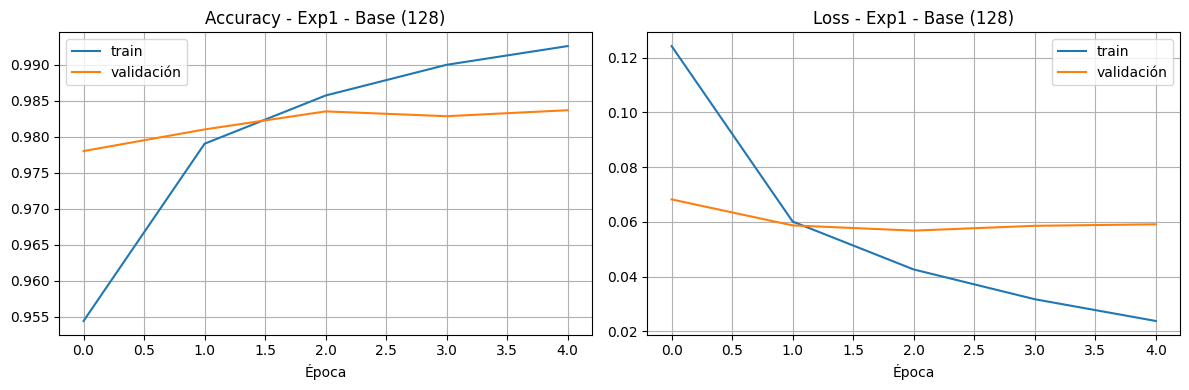

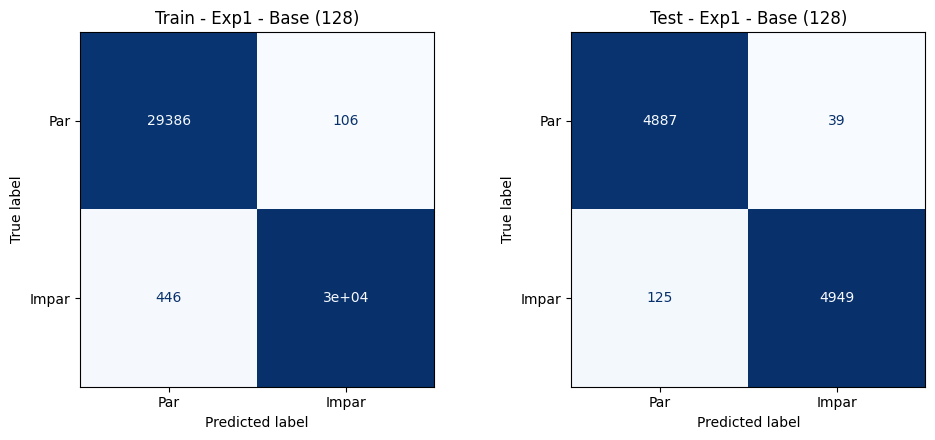

In [6]:
r1 = experimento_binario('Exp1 - Base (128)', build_base)
resultados.append(r1)

Exp2 - Base + Dropout(0.3)  (100,609 parámetros)
  Tiempo entrenamiento: 48.0 s
  Train -> accuracy=0.9875  loss=0.0373  errores=753
  Test  -> accuracy=0.9815  loss=0.0525  errores=185


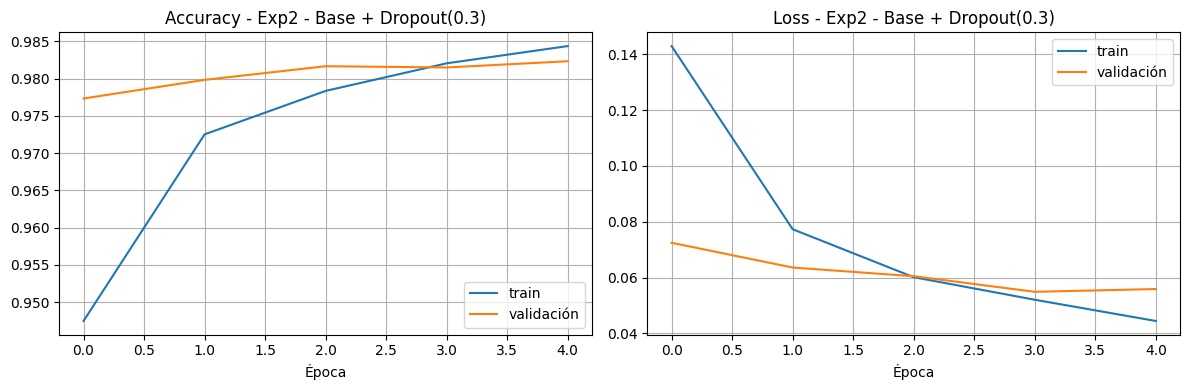

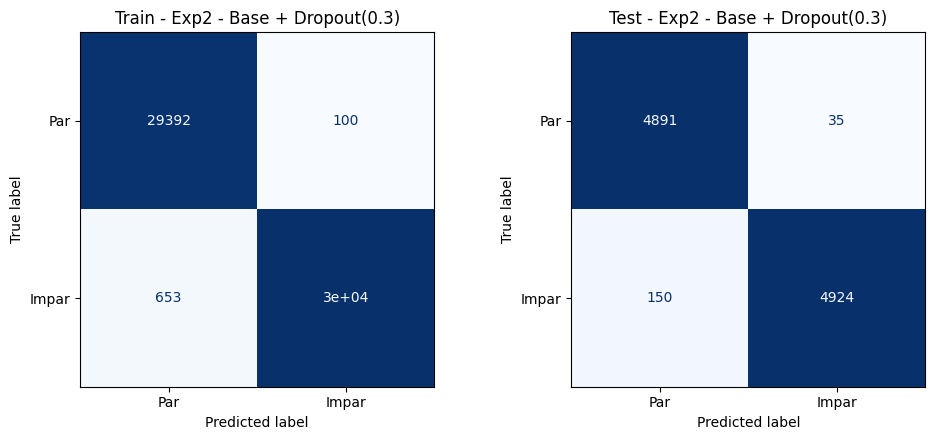

In [7]:
r2 = experimento_binario('Exp2 - Base + Dropout(0.3)', build_dropout)
resultados.append(r2)

Exp3 - + Dense(64) extra  (108,801 parámetros)
  Tiempo entrenamiento: 52.3 s
  Train -> accuracy=0.9903  loss=0.0301  errores=580
  Test  -> accuracy=0.9821  loss=0.0617  errores=179


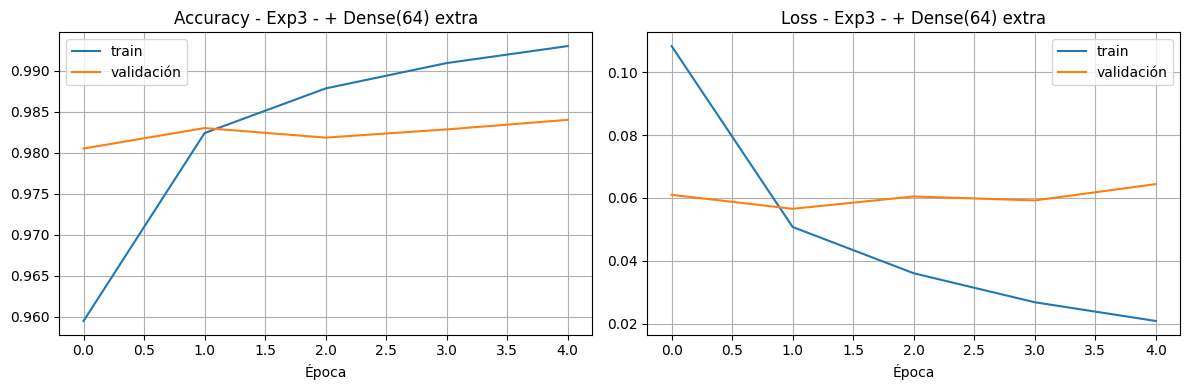

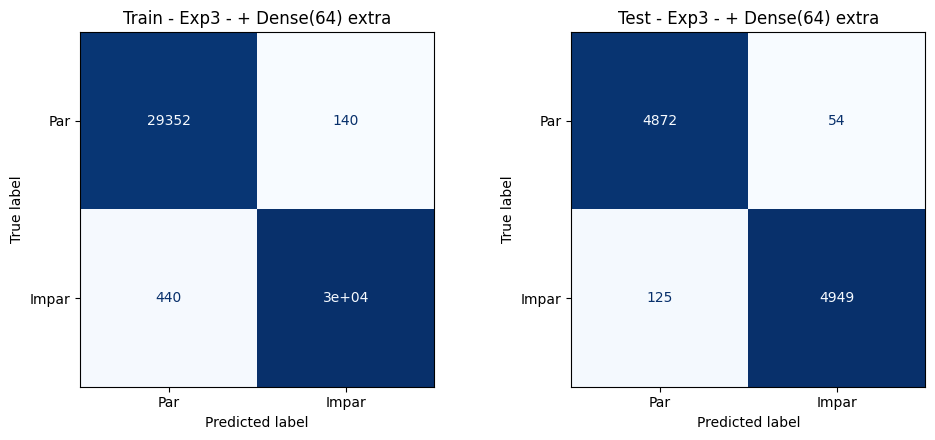

In [8]:
r3 = experimento_binario('Exp3 - + Dense(64) extra', build_extra_dense)
resultados.append(r3)

Exp4 - Dense(64) + Dropout  (108,801 parámetros)
  Tiempo entrenamiento: 57.9 s
  Train -> accuracy=0.9886  loss=0.0338  errores=686
  Test  -> accuracy=0.9843  loss=0.0494  errores=157


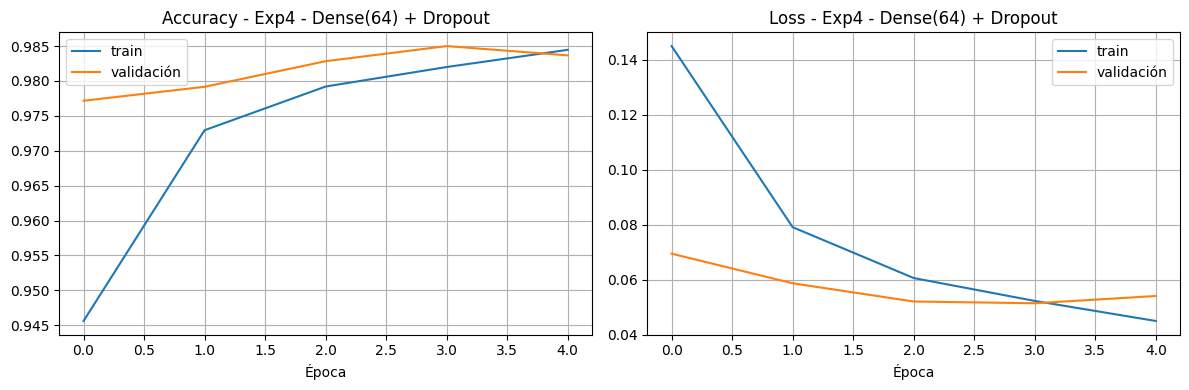

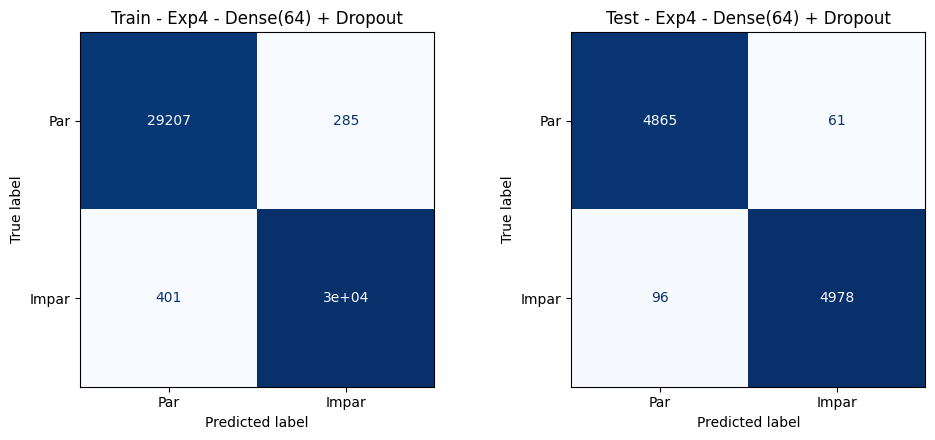

In [9]:
r4 = experimento_binario('Exp4 - Dense(64) + Dropout', build_extra_dense_dropout)
resultados.append(r4)

Exp5 - Red pequeña (32)  (25,153 parámetros)
  Tiempo entrenamiento: 31.3 s
  Train -> accuracy=0.9843  loss=0.0470  errores=945
  Test  -> accuracy=0.9786  loss=0.0635  errores=214


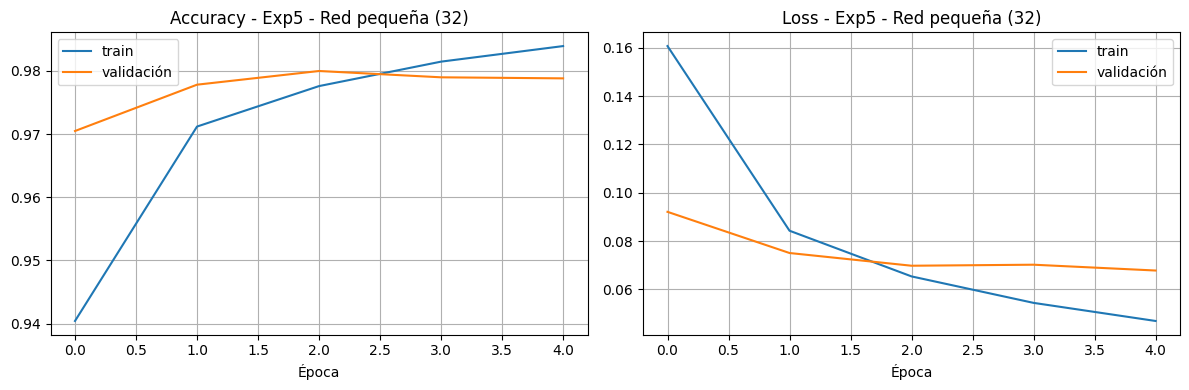

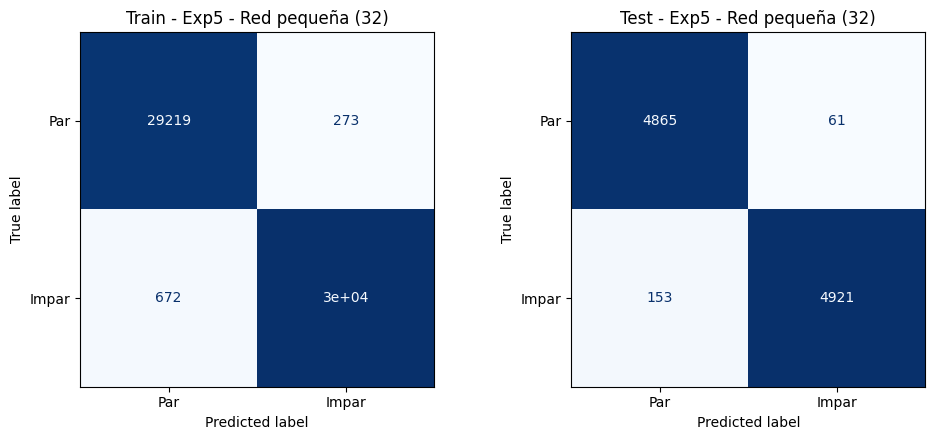

In [10]:
r5 = experimento_binario('Exp5 - Red pequeña (32)', build_small)
resultados.append(r5)

## 5. Comparación conjunta

La columna **Diferencia train-test** es un indicador rápido de sobreajuste: cuanto mayor, más está memorizando el modelo el conjunto de entrenamiento en vez de generalizar.

In [11]:
tabla = pd.DataFrame([{
    'Experimento': r['nombre'],
    'Parámetros': r['parametros'],
    'Accuracy train': round(r['train_acc'], 4),
    'Errores train': r['err_train'],
    'Accuracy test': round(r['test_acc'], 4),
    'Errores test': r['err_test'],
    'Loss test': round(r['test_loss'], 4),
    'Diferencia train-test': round(r['train_acc'] - r['test_acc'], 4),
    'Tiempo (s)': r['tiempo_s'],
} for r in resultados]).sort_values('Accuracy test', ascending=False).reset_index(drop=True)

tabla

,Experimento,Parámetros,Accuracy train,Errores train,Accuracy test,Errores test,Loss test,Diferencia train-test,Tiempo (s)
0,Exp4 - Dense(64) + Dropout,108801,0.9886,686,0.9843,157,0.0494,0.0043,57.90
1,Exp1 - Base (128),100609,0.9908,552,0.9836,164,0.0521,0.0072,53.73
2,Exp3 - + Dense(64) extra,108801,0.9903,580,0.9821,179,0.0617,0.0082,52.30
3,Exp2 - Base + Dropout(0.3),100609,0.9875,753,0.9815,185,0.0525,0.0059,48.03
4,Exp5 - Red pequeña (32),25153,0.9843,945,0.9786,214,0.0635,0.0056,31.26


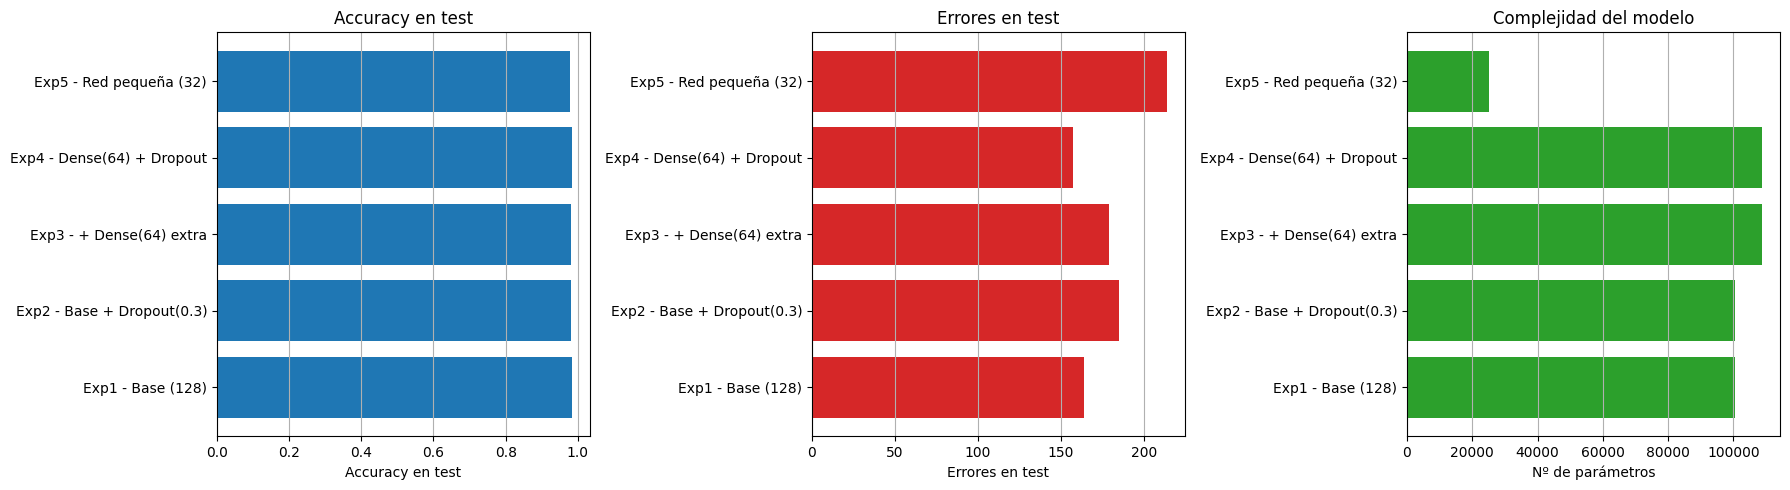

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
nombres = [r['nombre'] for r in resultados]

ax[0].barh(nombres, [r['test_acc'] for r in resultados], color='tab:blue')
ax[0].set_xlabel('Accuracy en test'); ax[0].set_title('Accuracy en test'); ax[0].grid(True, axis='x')

ax[1].barh(nombres, [r['err_test'] for r in resultados], color='tab:red')
ax[1].set_xlabel('Errores en test'); ax[1].set_title('Errores en test'); ax[1].grid(True, axis='x')

ax[2].barh(nombres, [r['parametros'] for r in resultados], color='tab:green')
ax[2].set_xlabel('Nº de parámetros'); ax[2].set_title('Complejidad del modelo'); ax[2].grid(True, axis='x')

plt.tight_layout()
plt.show()

La arquitectura con mejor accuracy de test es Exp4 (Dense(64) + Dropout(0.3)), con 0,9843, 157 errores sobre 10.000. Además de ganar en accuracy, Exp4 tiene la menor diferencia train-test de las cinco 0,0043, así que no es un ganador "por los pelos": generaliza mejor que el resto.

La red pequeña, la Exp5, es la que peor resultado da 0,9786 y la que más errores comete 214.

## 6. Paso opcional

Exp6 - Arquitectura ganadora, epochs=10  (108,801 parámetros)
  Tiempo entrenamiento: 115.8 s
  Train -> accuracy=0.9938  loss=0.0198  errores=374
  Test  -> accuracy=0.9867  loss=0.0456  errores=133


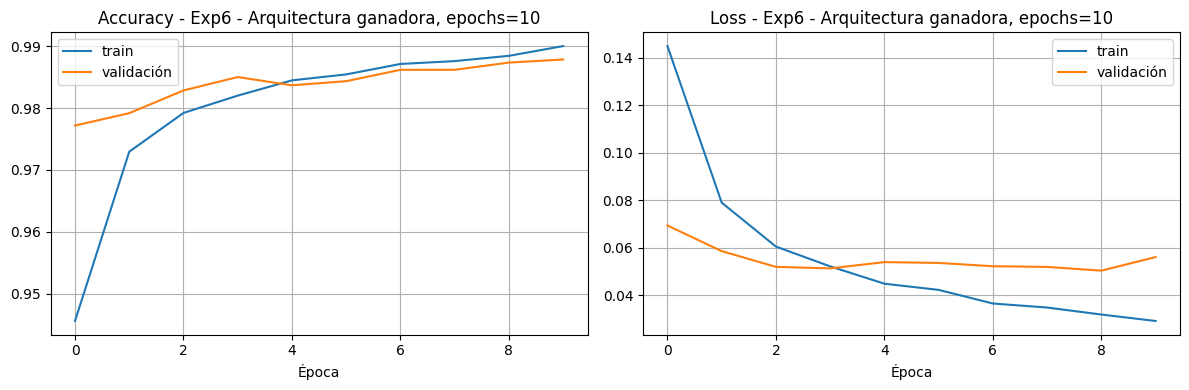

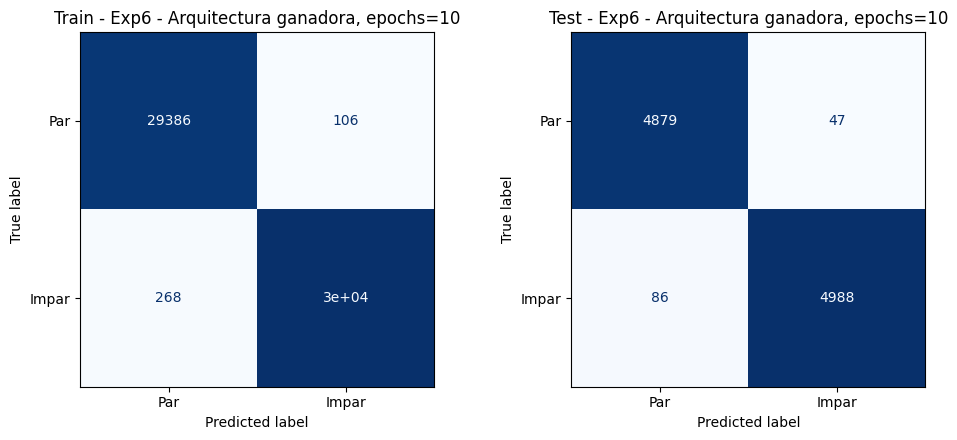

In [16]:
build_fn_ganadora = build_extra_dense_dropout  # Exp4 fue la ganadora

r6 = experimento_binario('Exp6 - Arquitectura ganadora, epochs=10', build_fn_ganadora, epochs=10)
resultados.append(r6)

A diferencia de lo que pasaba en la Práctica 1 al pasar de 5 a 15 épocas con Adam, donde el train accuracy subía pero el test se quedaba igual o empeoraba, aquí sí hay una mejora real al entrenar la arquitectura ganadora Exp4 el doble de épocas.

La clave es que no solo sube la accuracy de test, también baja el loss de test (0,0494 → 0,0456). Si fuera sobreajuste puro, como pasó con la base en la primera versión de este experimento, esperaríamos ver el loss de test empeorar aunque la accuracy se mantuviera. Aquí mejoran las dos cosas a la vez, así que el modelo sigue generalizando mejor, no memorizando.

## 7. Guardado del mejor modelo

In [17]:
mejor = max(resultados, key=lambda r: r['test_acc'])
nombre_archivo = 'mejor_modelo_par_impar.keras'
mejor['modelo'].save(nombre_archivo)
tabla_final = pd.DataFrame([{
    'Experimento': r['nombre'], 'Parámetros': r['parametros'],
    'Accuracy test': round(r['test_acc'], 4), 'Errores test': r['err_test'],
    'Tiempo (s)': r['tiempo_s'],
} for r in resultados]).sort_values('Accuracy test', ascending=False).reset_index(drop=True)
tabla_final.to_csv('resultados_experimentos_par_impar.csv', index=False)

print(f'Modelo guardado: {nombre_archivo}')
print(f'Configuración: {mejor["nombre"]} | accuracy test = {mejor["test_acc"]:.4f} | errores test = {mejor["err_test"]}')

# Para cargarlo más adelante:
# modelo_cargado = tf.keras.models.load_model('mejor_modelo_par_impar.keras')

Modelo guardado: mejor_modelo_par_impar.keras
Configuración: Exp6 - Arquitectura ganadora, epochs=10 | accuracy test = 0.9867 | errores test = 133


## 8. Conclusión

La mejor configuración encontrada es Exp6: arquitectura Dense(64) + Dropout(0.3), entrenada con Adam durante 10 épocas, con 0,9867 de accuracy en test, 133 errores sobre 10.000, y un loss de test de 0,0456. Es la que gana en las dos métricas que más importan, accuracy y errores, y aunque tiene algo más de diferencia train-test que su versión de 5 épocas, 0,0071 frente a 0,0043, sigue siendo una diferencia pequeña: no hay señales claras de sobreajuste, ya que el loss de test también mejora en vez de empeorar.

El único coste a tener en cuenta es el tiempo: 115,8 s frente a los 53,7 s de la arquitectura base con 5 épocas, más del doble, por una ganancia de 0,31 puntos de accuracy y 31 errores menos. Si el criterio de selección diera más peso al tiempo de entrenamiento que a exprimir el último punto de accuracy, Exp4, misma arquitectura, 5 épocas: 0,9843, 157 errores, 57,9 s, seguiría siendo una alternativa muy razonable con la mitad de coste computacional.